In [ ]:

import ipywidgets as widgets
from IPython.display import display, clear_output
import matplotlib.pyplot as plt
import numpy as np

# ----------------------------
# Architecture stages
# ----------------------------

stages = [
    {
        "title": "01 - Input Data",
        "description": "Open-i dataset provides frontal chest X-rays, "
                       "clinical indications and ground-truth labels.",
        "details": ["Image: img_frontal",
                    "Text: indication",
                    "Labels: Problems"]
    },
    {
        "title": "02 - Image Encoder",
        "description": "The frozen ViT divides the 224x224 image "
                       "into 196 patches and adds a CLS token.",
        "details": ["Image size: 224 x 224",
                    "Patch size: 16 x 16",
                    "Tokens: 197",
                    "Embedding: 768"]
    },
    {
        "title": "03 - Text Encoder",
        "description": "PubMedBERT processes the clinical indication "
                       "and generates contextualized text embeddings.",
        "details": ["Maximum tokens: 64",
                    "Embedding: 768",
                    "Padding mask applied"]
    },
    {
        "title": "04 - Feature Extraction",
        "description": "Both pretrained encoders remain frozen. "
                       "Extracted features are cached.",
        "details": ["Image: (N, 197, 768)",
                    "Text: (N, 64, 768)",
                    "Cache: openi_biomedclip_feats.pt"]
    },
    {
        "title": "05 - Multimodal Fusion",
        "description": "Image and text embeddings are projected "
                       "to 256 dimensions and concatenated.",
        "details": ["Image: 197 tokens",
                    "Text: 64 tokens",
                    "Learnable CLS: 1 token",
                    "Total: 262 tokens"]
    },
    {
        "title": "06 - Transformer",
        "description": "Two fusion layers use multi-head attention "
                       "to learn relationships between modalities.",
        "details": ["Layers: 2",
                    "Attention heads: 4",
                    "Dropout: 0.1",
                    "Dimension: 256"]
    },
    {
        "title": "07 - Classification",
        "description": "The fused CLS token is used to predict "
                       "eight findings.",
        "details": ["LayerNorm + Linear",
                    "Sigmoid probabilities",
                    "BCEWithLogitsLoss"]
    }
]

# ----------------------------
# Widgets
# ----------------------------

output = widgets.Output()

previous_btn = widgets.Button(
    description="Previous",
    icon="arrow-left"
)

next_btn = widgets.Button(
    description="Next",
    icon="arrow-right",
    button_style="primary"
)

stage_slider = widgets.IntSlider(
    value=0,
    min=0,
    max=len(stages)-1,
    description="Stage:",
    continuous_update=False
)

# ----------------------------
# Visualization
# ----------------------------

def draw_stage(index):

    stage = stages[index]

    with output:
        clear_output(wait=True)

        fig, ax = plt.subplots(figsize=(10, 4))
        ax.set_xlim(0, 10)
        ax.set_ylim(0, 5)
        ax.axis("off")

        ax.text(
            5, 4.5,
            stage["title"],
            ha="center",
            fontsize=19,
            weight="bold"
        )

        # Draw architecture blocks
        if index == 0:
            blocks = [
                ("Chest X-ray", 2, "#d1fae5"),
                ("Clinical text", 6, "#ede9fe")
            ]

        elif index == 1:
            blocks = [
                ("224 x 224 image", 1, "#d1fae5"),
                ("196 patches + CLS", 6, "#d1fae5")
            ]

        elif index == 2:
            blocks = [
                ("Clinical indication", 1, "#ede9fe"),
                ("64 text tokens", 6, "#ede9fe")
            ]

        elif index == 3:
            blocks = [
                ("Frozen ViT", 1, "#d1fae5"),
                ("Frozen PubMedBERT", 6, "#ede9fe")
            ]

        elif index == 4:
            blocks = [
                ("Image tokens", 1, "#d1fae5"),
                ("Text tokens", 4, "#ede9fe"),
                ("262 joint tokens", 7, "#fed7aa")
            ]

        elif index == 5:
            blocks = [
                ("Fusion layer 1", 1, "#fed7aa"),
                ("Fusion layer 2", 6, "#fed7aa")
            ]

        else:
            blocks = [
                ("Fused CLS", 1, "#fed7aa"),
                ("8 predictions", 6, "#bfdbfe")
            ]

        for label, x, color in blocks:

            ax.text(
                x, 2.8,
                label,
                ha="center",
                va="center",
                fontsize=11,
                bbox=dict(
                    boxstyle="round,pad=0.8",
                    facecolor=color,
                    edgecolor="gray"
                )
            )

        # Add arrows between blocks
        for i in range(len(blocks)-1):
            x1 = blocks[i][1] + 1
            x2 = blocks[i+1][1] - 1

            ax.annotate(
                "",
                xy=(x2, 2.8),
                xytext=(x1, 2.8),
                arrowprops=dict(
                    arrowstyle="->",
                    lw=2
                )
            )

        ax.text(
            5, 1.3,
            stage["description"],
            ha="center",
            fontsize=11,
            wrap=True
        )

        ax.text(
            5, 0.5,
            " | ".join(stage["details"]),
            ha="center",
            fontsize=9,
            color="gray"
        )

        plt.show()


# ----------------------------
# Navigation
# ----------------------------

def update_stage(index):

    index = max(0, min(index, len(stages)-1))

    stage_slider.value = index

    previous_btn.disabled = index == 0
    next_btn.description = (
        "Restart" if index == len(stages)-1 else "Next"
    )

    draw_stage(index)


def on_next(_):
    new_index = (
        0 if stage_slider.value == len(stages)-1
        else stage_slider.value + 1
    )
    update_stage(new_index)


def on_previous(_):
    update_stage(stage_slider.value - 1)


def on_slider_change(change):
    if change["name"] == "value":
        update_stage(change["new"])


next_btn.on_click(on_next)
previous_btn.on_click(on_previous)
stage_slider.observe(on_slider_change)

# ----------------------------
# Display
# ----------------------------

display(
    widgets.VBox([
        widgets.HTML("<h2>BiomedCLIP Architecture Explorer</h2>"),
        stage_slider,
        output,
        widgets.HBox([
            previous_btn,
            next_btn
        ])
    ])
)

update_stage(0)


In [9]:

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.animation as animation
import matplotlib.patches as patches

from PIL import Image
from IPython.display import HTML, display

# -----------------------------
# Configuration
# -----------------------------

IMAGE_PATH = "chest_xray.jpg"

GRID = 14
TOTAL_PATCHES = GRID * GRID
IMAGE_SIZE = 224

# Load and resize image
img = Image.open(IMAGE_PATH).convert("RGB")
img = img.resize((IMAGE_SIZE, IMAGE_SIZE))

img_array = np.array(img)

# Split image into 196 patches
patches_list = []

patch_size = IMAGE_SIZE // GRID

for row in range(GRID):
    for col in range(GRID):

        y1 = row * patch_size
        y2 = y1 + patch_size

        x1 = col * patch_size
        x2 = x1 + patch_size

        patch = img_array[y1:y2, x1:x2]

        patches_list.append(patch)

# -----------------------------
# Animation layout
# -----------------------------

fig = plt.figure(figsize=(12, 7))

ax1 = fig.add_axes([0.05, 0.18, 0.42, 0.70])
ax2 = fig.add_axes([0.55, 0.18, 0.42, 0.70])

fig.suptitle(
    "Vision Transformer: Image Patch Extraction",
    fontsize=18,
    fontweight="bold"
)

# Original image
ax1.imshow(img_array)
ax1.set_title("Input: 224 × 224")
ax1.axis("off")

# Patch visualization
ax2.imshow(img_array)
ax2.set_title("Extracting patches")
ax2.axis("off")

# Counter
counter = fig.text(
    0.5, 0.08,
    "Patches extracted: 0 / 196",
    ha="center",
    fontsize=14
)

# -----------------------------
# Animation frames
# -----------------------------

# Phase 1: Draw grid
GRID_FRAMES = 30

# Phase 2: Highlight patches
PATCH_FRAMES = TOTAL_PATCHES

# Phase 3: Separate patches
SEPARATE_FRAMES = TOTAL_PATCHES

TOTAL_FRAMES = (
    GRID_FRAMES +
    PATCH_FRAMES +
    SEPARATE_FRAMES
)

def update(frame):

    ax2.clear()

    # -------------------------
    # Phase 1: Grid appears
    # -------------------------

    if frame < GRID_FRAMES:

        ax2.imshow(img_array)

        progress = (frame + 1) / GRID_FRAMES

        for i in range(GRID + 1):

            if i / GRID <= progress:

                ax2.axhline(
                    i * patch_size - 0.5,
                    color="lime",
                    linewidth=1
                )

                ax2.axvline(
                    i * patch_size - 0.5,
                    color="lime",
                    linewidth=1
                )

        ax2.set_title("Dividing image into 14 × 14 patches")
        ax2.axis("off")

        counter.set_text("Creating 14 × 14 grid")

    # -------------------------
    # Phase 2: Highlight patches
    # -------------------------

    elif frame < GRID_FRAMES + PATCH_FRAMES:

        patch_index = frame - GRID_FRAMES + 1

        ax2.imshow(img_array)

        for i in range(patch_index):

            row = i // GRID
            col = i % GRID

            rect = patches.Rectangle(
                (col * patch_size, row * patch_size),
                patch_size,
                patch_size,
                linewidth=0.7,
                edgecolor="yellow",
                facecolor="yellow",
                alpha=0.45
            )

            ax2.add_patch(rect)

        ax2.set_title("Extracting individual image patches")
        ax2.axis("off")

        counter.set_text(
            f"Patches extracted: {patch_index} / 196"
        )

    # -------------------------
    # Phase 3: Separate patches
    # -------------------------

    else:

        separated_frame = (
            frame - GRID_FRAMES - PATCH_FRAMES
        )

        # Number of patches revealed
        visible = min(separated_frame + 1, TOTAL_PATCHES)

        ax2.set_xlim(-0.5, GRID + 0.5)
        ax2.set_ylim(GRID + 0.5, -0.5)
        ax2.set_aspect("equal")

        ax2.set_xticks([])
        ax2.set_yticks([])

        for i in range(visible):

            row = i // GRID
            col = i % GRID

            patch = patches_list[i]

            ax2.imshow(
                patch,
                extent=[
                    col - 0.42,
                    col + 0.42,
                    row + 0.42,
                    row - 0.42
                ]
            )

        ax2.set_title("196 individual image patches")

        counter.set_text(
            f"Separated patches: {visible} / 196"
        )

    return []

# -----------------------------
# Render animation
# -----------------------------

ani = animation.FuncAnimation(
    fig,
    update,
    frames=TOTAL_FRAMES,
    interval=35,
    blit=False,
    repeat=True
)

plt.close(fig)

display(
    HTML(
        ani.to_jshtml(
            fps=25,
            default_mode="loop"
        )
    )
)

[10/30/26 02:49:16] INFO     Animation.save using <class 'matplotlib.animation.HTMLWriter'>       ]8;id=3886349;file:///opt/miniconda3/envs/ece-425/lib/python3.12/site-packages/matplotlib/animation.py\animation.py]8;;\:]8;id=3886350;file:///opt/miniconda3/envs/ece-425/lib/python3.12/site-packages/matplotlib/animation.py#1096\1096]8;;\

[10/30/26 02:49:31] WARNING  Animation size has reached 21206694 bytes, exceeding the limit of     ]8;id=3886356;file:///opt/miniconda3/envs/ece-425/lib/python3.12/site-packages/matplotlib/animation.py\animation.py]8;;\:]8;id=3886357;file:///opt/miniconda3/envs/ece-425/lib/python3.12/site-packages/matplotlib/animation.py#810\810]8;;\
                             20971520.0. If you're sure you want a larger animation embedded, set                  
                             the animation.embed_limit rc parameter to a larger value (in MB).                     
                             This and further frames will be dropped.                                              

In [11]:

# ============================================================
# NEXT STAGE: Transform Image Patches into Flattened Vectors
# ============================================================

# Each patch: 16 x 16 x 3
# Each flattened vector: 768 dimensions
# Total vectors: 196

PATCH_DIM = patch_size * patch_size * 3

# Flatten all patches
vectors_list = [
    patch.flatten()
    for patch in patches_list
]

# -----------------------------
# Animation configuration
# -----------------------------

FRAMES_PER_PATCH = 12
TOTAL_FRAMES = TOTAL_PATCHES * FRAMES_PER_PATCH

fig = plt.figure(figsize=(14, 7))

ax1 = fig.add_axes([0.04, 0.23, 0.25, 0.65])
ax2 = fig.add_axes([0.36, 0.35, 0.60, 0.45])

fig.suptitle(
    "Vision Transformer: Patch-to-Vector Transformation",
    fontsize=17,
    fontweight="bold"
)

# Left: selected image patch
ax1.set_title("Selected image patch", fontsize=13)
ax1.axis("off")

# Right: flattened vector
ax2.set_title("Flattening RGB pixel values", fontsize=13)
ax2.set_xlabel("Vector dimensions")
ax2.set_ylabel("RGB pixel values")

# Progress counter
counter = fig.text(
    0.5, 0.12,
    "",
    ha="center",
    fontsize=13
)

# Vector dimension information
dimension_text = fig.text(
    0.5, 0.07,
    "",
    ha="center",
    fontsize=11
)

# -----------------------------
# Animation update
# -----------------------------

def update_vector(frame):

    ax1.clear()
    ax2.clear()

    # Determine current patch
    patch_index = frame // FRAMES_PER_PATCH

    # Progress within current patch
    step = frame % FRAMES_PER_PATCH

    patch = patches_list[patch_index]
    vector = vectors_list[patch_index]

    # Number of vector elements revealed
    visible_dimensions = int(
        (step + 1) / FRAMES_PER_PATCH * PATCH_DIM
    )

    # -------------------------
    # LEFT: Original patch
    # -------------------------

    ax1.imshow(patch)

    ax1.set_title(
        f"Image patch {patch_index + 1}/{TOTAL_PATCHES}",
        fontsize=13
    )

    ax1.axis("off")

    # -------------------------
    # RIGHT: Flattened vector
    # -------------------------

    ax2.set_xlim(0, PATCH_DIM)
    ax2.set_ylim(-5, 260)

    ax2.set_xlabel("Vector dimensions")
    ax2.set_ylabel("Pixel intensity")

    ax2.set_title(
        f"Flattened vector: {visible_dimensions}/{PATCH_DIM} values",
        fontsize=13
    )

    # Draw revealed vector values
    ax2.plot(
        np.arange(visible_dimensions),
        vector[:visible_dimensions],
        color="royalblue",
        linewidth=0.8
    )

    # Highlight current position
    if visible_dimensions > 0:

        ax2.scatter(
            visible_dimensions - 1,
            vector[visible_dimensions - 1],
            color="red",
            s=20,
            zorder=3
        )

    ax2.grid(alpha=0.2)

    # -------------------------
    # Progress information
    # -------------------------

    counter.set_text(
        f"Processing patch {patch_index + 1} / {TOTAL_PATCHES}"
    )

    dimension_text.set_text(
        f"Patch shape: {patch.shape}     |     "
        f"Vector dimension: {PATCH_DIM}"
    )

    return []

# -----------------------------
# Render animation
# -----------------------------

vector_animation = animation.FuncAnimation(
    fig,
    update_vector,
    frames=TOTAL_FRAMES,
    interval=50,
    blit=False,
    repeat=True
)

plt.close(fig)

display(
    HTML(
        vector_animation.to_jshtml(
            fps=20,
            default_mode="loop"
        )
    )
)

[10/30/26 03:00:52] INFO     Animation.save using <class 'matplotlib.animation.HTMLWriter'>       ]8;id=3886362;file:///opt/miniconda3/envs/ece-425/lib/python3.12/site-packages/matplotlib/animation.py\animation.py]8;;\:]8;id=3886363;file:///opt/miniconda3/envs/ece-425/lib/python3.12/site-packages/matplotlib/animation.py#1096\1096]8;;\

[10/30/26 03:01:40] WARNING  Animation size has reached 21010305 bytes, exceeding the limit of     ]8;id=3886368;file:///opt/miniconda3/envs/ece-425/lib/python3.12/site-packages/matplotlib/animation.py\animation.py]8;;\:]8;id=3886369;file:///opt/miniconda3/envs/ece-425/lib/python3.12/site-packages/matplotlib/animation.py#810\810]8;;\
                             20971520.0. If you're sure you want a larger animation embedded, set                  
                             the animation.embed_limit rc parameter to a larger value (in MB).                     
                             This and further frames will be dropped.                                              

In [13]:

# =====================================================
# Image Patch → Vector → Matrix
# With dimensions displayed during animation
# =====================================================

patch = patches_list[0]
vector = patch.flatten()

FRAMES = 90

fig = plt.figure(figsize=(13, 6))

ax1 = fig.add_axes([0.04, 0.25, 0.25, 0.58])
ax2 = fig.add_axes([0.36, 0.25, 0.60, 0.58])

fig.suptitle(
    "Vision Transformer: Patch Embedding Preparation",
    fontsize=17,
    fontweight="bold"
)

def update(frame):

    ax1.clear()
    ax2.clear()

    # -------------------------
    # Stage 1: Image patch
    # -------------------------

    if frame < 20:

        ax1.imshow(patch)
        ax1.set_title(
            "Image Patch\nSize: 16 × 16 × 3",
            fontsize=14
        )
        ax1.axis("off")

        ax2.axis("off")
        ax2.text(
            0.5, 0.5,
            "One image patch\n\n16 × 16 × 3",
            ha="center",
            va="center",
            fontsize=18,
            transform=ax2.transAxes
        )

    # -------------------------
    # Stage 2: Flatten to vector
    # -------------------------

    elif frame < 50:

        progress = (frame - 20) / 30
        visible = max(1, int(progress * len(vector)))

        ax1.imshow(patch)
        ax1.set_title("Original Patch")
        ax1.axis("off")

        ax2.plot(
            vector[:visible],
            color="royalblue",
            linewidth=1
        )

        ax2.set_xlim(0, len(vector))
        ax2.set_ylim(0, 255)

        ax2.set_title(
            f"Flattened Vector\nSize: 768 × 1",
            fontsize=14
        )

        ax2.set_xlabel("768 dimensions")
        ax2.set_ylabel("Pixel intensity")
        ax2.grid(alpha=0.2)

        ax2.text(
            0.98, 0.95,
            f"{visible} / 768 values",
            transform=ax2.transAxes,
            ha="right",
            va="top",
            fontsize=12,
            bbox=dict(facecolor="white", alpha=0.8)
        )

    # -------------------------
    # Stage 3: Stack vectors
    # -------------------------

    else:

        progress = min(1, (frame - 50) / 30)

        n = max(1, int(progress * 12))

        matrix = np.array([
            p.flatten()
            for p in patches_list[:n]
        ])

        ax1.axis("off")
        ax1.text(
            0.5, 0.5,
            "Multiple image patches",
            ha="center",
            va="center",
            fontsize=16,
            transform=ax1.transAxes
        )

        ax2.imshow(
            matrix,
            aspect="auto",
            cmap="viridis",
            interpolation="nearest"
        )

        ax2.set_title(
            f"Stacked Patch Vectors\nMatrix Size: {n} × 768",
            fontsize=14
        )

        ax2.set_xlabel("768 features (columns)")
        ax2.set_ylabel(f"{n} patch vectors (rows)")

        ax2.text(
            0.98, 0.95,
            f"Shape: ({n}, 768)",
            transform=ax2.transAxes,
            ha="right",
            va="top",
            fontsize=13,
            color="white",
            bbox=dict(facecolor="black", alpha=0.7)
        )

    return []

ani = animation.FuncAnimation(
    fig,
    update,
    frames=FRAMES,
    interval=70,
    blit=False,
    repeat=True
)

plt.close(fig)

display(HTML(ani.to_jshtml(fps=15)))


[10/30/26 03:07:45] INFO     Animation.save using <class 'matplotlib.animation.HTMLWriter'>       ]8;id=3886380;file:///opt/miniconda3/envs/ece-425/lib/python3.12/site-packages/matplotlib/animation.py\animation.py]8;;\:]8;id=3886381;file:///opt/miniconda3/envs/ece-425/lib/python3.12/site-packages/matplotlib/animation.py#1096\1096]8;;\

In [4]:

# =====================================================
# Words → Tokens → Vectors
# Simple embedding visualization
# =====================================================

import matplotlib.pyplot as plt
import matplotlib.animation as animation
from matplotlib.patches import Rectangle
from IPython.display import HTML, display

tokens = ["The", "lungs", "look", "healthy"]

FRAMES = 90
VECTOR_SQUARES = 10

fig, ax = plt.subplots(figsize=(11, 5))

fig.suptitle(
    "Words → Embedding Vectors",
    fontsize=18,
    fontweight="bold"
)

def update(frame):

    ax.clear()
    ax.axis("off")
    ax.set_xlim(0, 12)
    ax.set_ylim(0, 7)

    # Stage 1: Words
    if frame < 20:

        ax.text(
            6, 5.5,
            "The lungs look healthy",
            ha="center",
            fontsize=22
        )

        ax.text(
            6, 3,
            "Input sentence",
            ha="center",
            fontsize=14,
            color="gray"
        )

    # Stage 2: Tokens
    elif frame < 40:

        ax.text(
            6, 6,
            "Tokenization",
            ha="center",
            fontsize=16
        )

        for i, word in enumerate(tokens):

            x = 1.5 + i * 2.7

            ax.text(
                x, 3.5,
                word,
                ha="center",
                va="center",
                fontsize=17,
                bbox=dict(
                    boxstyle="round,pad=0.5",
                    facecolor="lightblue",
                    edgecolor="steelblue"
                )
            )

    # Stage 3: Tokens become vectors
    else:

        progress = min(1, (frame - 40) / 30)

        visible = max(
            1,
            min(4, int(progress * 4) + 1)
        )

        ax.text(
            6, 6.3,
            "Each token becomes an embedding vector",
            ha="center",
            fontsize=16
        )

        for i, word in enumerate(tokens[:visible]):

            x = 1.5 + i * 2.7

            # Token label
            ax.text(
                x, 5,
                word,
                ha="center",
                fontsize=16
            )

            ax.annotate(
                "",
                xy=(x, 4.3),
                xytext=(x, 4.7),
                arrowprops=dict(
                    arrowstyle="->",
                    color="gray"
                )
            )

            # Stack of squares representing vector
            for j in range(VECTOR_SQUARES):

                square = Rectangle(
                    (x - 0.22, 0.6 + j * 0.32),
                    0.44,
                    0.27,
                    facecolor=plt.cm.viridis(j / VECTOR_SQUARES),
                    edgecolor="white"
                )

                ax.add_patch(square)

        ax.text(
            6, 0.1,
            "Each vector actually contains 768 dimensions",
            ha="center",
            fontsize=14,
            fontweight="bold"
        )

ani = animation.FuncAnimation(
    fig,
    update,
    frames=FRAMES,
    interval=100,
    blit=False,
    repeat=True
)

plt.close(fig)

display(HTML(ani.to_jshtml(fps=12)))

In [5]:

# =====================================================
# IMAGE + TEXT → MULTIMODAL FUSION
# Visualization of the BiomedCLIP Fusion Head
# =====================================================

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.animation as animation
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch
from IPython.display import HTML, display

FRAMES = 120

fig, ax = plt.subplots(figsize=(14, 7))

fig.suptitle(
    "Multimodal Transformer: Image + Text Fusion",
    fontsize=18,
    fontweight="bold"
)

def box(x, y, w, h, label, color, fontsize=12):
    patch = FancyBboxPatch(
        (x, y), w, h,
        boxstyle="round,pad=0.08",
        facecolor=color,
        edgecolor="gray",
        linewidth=1.3
    )
    ax.add_patch(patch)
    ax.text(
        x + w/2, y + h/2,
        label,
        ha="center",
        va="center",
        fontsize=fontsize,
        wrap=True
    )

def arrow(x1, y1, x2, y2):
    ax.add_patch(FancyArrowPatch(
        (x1, y1), (x2, y2),
        arrowstyle="->",
        mutation_scale=16,
        color="gray",
        linewidth=1.5
    ))

def update(frame):

    ax.clear()
    ax.set_xlim(0, 14)
    ax.set_ylim(0, 8)
    ax.axis("off")

    # ---------------------------------
    # Stage 1: Two input modalities
    # ---------------------------------

    if frame < 20:

        ax.text(7, 7.2, "Two different input representations",
                ha="center", fontsize=16)

        box(0.7, 4.5, 3.2, 1.3,
            "IMAGE TOKENS\n197 × 768\n[CLS] + 196 patches",
            "lightblue")

        box(0.7, 1.8, 3.2, 1.3,
            "TEXT TOKENS\n64 × 768\nClinical text",
            "lightyellow")

        ax.text(7, 4.9, "Visual information",
                ha="center", fontsize=13, color="steelblue")

        ax.text(7, 2.2, "Clinical information",
                ha="center", fontsize=13, color="darkorange")

        ax.text(7, 0.7,
                "Both modalities contain 768-dimensional vectors",
                ha="center", fontsize=13)

    # ---------------------------------
    # Stage 2: Projection
    # ---------------------------------

    elif frame < 40:

        ax.text(7, 7.2, "Step 1: Project into a shared feature space",
                ha="center", fontsize=16)

        box(0.5, 4.7, 2.8, 1.1,
            "Image tokens\n197 × 768",
            "lightblue")

        box(0.5, 2.0, 2.8, 1.1,
            "Text tokens\n64 × 768",
            "lightyellow")

        arrow(3.4, 5.25, 5.0, 5.25)
        arrow(3.4, 2.55, 5.0, 2.55)

        box(5.1, 4.7, 3.0, 1.1,
            "Image projection\n768 → 256",
            "lightskyblue")

        box(5.1, 2.0, 3.0, 1.1,
            "Text projection\n768 → 256",
            "wheat")

        arrow(8.2, 5.25, 9.7, 5.25)
        arrow(8.2, 2.55, 9.7, 2.55)

        box(9.8, 4.7, 3.3, 1.1,
            "197 image vectors\n197 × 256",
            "lightblue")

        box(9.8, 2.0, 3.3, 1.1,
            "64 text vectors\n64 × 256",
            "lightyellow")

        ax.text(7, 0.7,
                "Both modalities now use the same 256-dimensional space",
                ha="center", fontsize=13)

    # ---------------------------------
    # Stage 3: Modality embeddings
    # ---------------------------------

    elif frame < 55:

        ax.text(7, 7.2, "Step 2: Add modality embeddings",
                ha="center", fontsize=16)

        box(1.0, 4.5, 4.5, 1.2,
            "Image vectors\n+ IMAGE modality embedding",
            "lightblue")

        box(1.0, 2.0, 4.5, 1.2,
            "Text vectors\n+ TEXT modality embedding",
            "lightyellow")

        arrow(5.7, 5.1, 7.2, 5.1)
        arrow(5.7, 2.6, 7.2, 2.6)

        box(7.3, 4.5, 5.0, 1.2,
            "Image tokens\n197 × 256",
            "lightskyblue")

        box(7.3, 2.0, 5.0, 1.2,
            "Text tokens\n64 × 256",
            "wheat")

        ax.text(7, 0.7,
                "Modality embeddings tell the Transformer where each token came from",
                ha="center", fontsize=12)

    # ---------------------------------
    # Stage 4: Concatenate
    # ---------------------------------

    elif frame < 75:

        ax.text(7, 7.2, "Step 3: Combine both modalities",
                ha="center", fontsize=16)

        box(0.5, 5.0, 3.2, 1.0,
            "Learnable [CLS]\n1 × 256",
            "plum")

        box(0.5, 3.3, 3.2, 1.0,
            "Image tokens\n197 × 256",
            "lightblue")

        box(0.5, 1.6, 3.2, 1.0,
            "Text tokens\n64 × 256",
            "lightyellow")

        arrow(3.8, 5.5, 5.2, 4.5)
        arrow(3.8, 3.8, 5.2, 4.1)
        arrow(3.8, 2.1, 5.2, 3.7)

        box(5.3, 3.3, 3.6, 1.6,
            "CONCATENATED SEQUENCE\n\n262 × 256",
            "lavender")

        arrow(9.0, 4.1, 10.1, 4.1)

        box(10.2, 3.3, 3.2, 1.6,
            "Combined token sequence\n\n[CLS] + Image + Text",
            "thistle")

        ax.text(7, 0.7,
                "1 + 197 + 64 = 262 tokens",
                ha="center", fontsize=14, fontweight="bold")

    # ---------------------------------
    # Stage 5: Transformer fusion
    # ---------------------------------

    elif frame < 100:

        ax.text(7, 7.2, "Step 4: Transformer learns cross-modal relationships",
                ha="center", fontsize=16)

        box(0.5, 3.5, 2.7, 1.5,
            "262 combined tokens\n262 × 256",
            "lavender")

        arrow(3.3, 4.25, 4.2, 4.25)

        box(4.3, 3.5, 2.7, 1.5,
            "TRANSFORMER\nLAYER 1",
            "lightsteelblue")

        arrow(7.1, 4.25, 8.0, 4.25)

        box(8.1, 3.5, 2.7, 1.5,
            "TRANSFORMER\nLAYER 2",
            "lightsteelblue")

        arrow(10.9, 4.25, 11.8, 4.25)

        box(11.9, 3.5, 1.7, 1.5,
            "FUSED\nTOKENS",
            "plum")

        ax.text(7, 2.4,
                "Image patches and clinical words can attend to one another",
                ha="center", fontsize=14)

        ax.text(7, 1.3,
                "Self-attention learns which visual and textual features are related",
                ha="center", fontsize=12, color="dimgray")

    # ---------------------------------
    # Stage 6: Classification
    # ---------------------------------

    else:

        ax.text(7, 7.2, "Step 5: Use the fused [CLS] representation",
                ha="center", fontsize=16)

        box(0.5, 4.0, 3.0, 1.5,
            "FUSED SEQUENCE\n262 × 256",
            "plum")

        arrow(3.6, 4.75, 4.7, 4.75)

        box(4.8, 4.0, 3.0, 1.5,
            "Extract [CLS]\n1 × 256",
            "thistle")

        arrow(7.9, 4.75, 9.0, 4.75)

        box(9.1, 4.0, 3.8, 1.5,
            "CLASSIFICATION HEAD\n8 predicted findings",
            "lightgreen")

        labels = [
            "Normal",
            "Lung",
            "Opacity",
            "Cardiomegaly",
            "Calcinosis",
            "Atelectasis",
            "Granuloma",
            "Thoracic vertebrae"
        ]

        ax.text(
            7, 2.5,
            "Predicted clinical findings",
            ha="center",
            fontsize=14,
            fontweight="bold"
        )

        for i, label in enumerate(labels):
            x = 1.0 + (i % 4) * 3.2
            y = 1.5 if i < 4 else 0.6

            box(x, y, 2.7, 0.55, label, "honeydew", fontsize=10)

ani = animation.FuncAnimation(
    fig,
    update,
    frames=FRAMES,
    interval=90,
    blit=False,
    repeat=True
)

plt.close(fig)

display(HTML(ani.to_jshtml(fps=12)))


/var/folders/_y/j2cg7l1j4196l1jz_2jjgm_40000gp/T/ipykernel_60064/1652109747.py:232: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


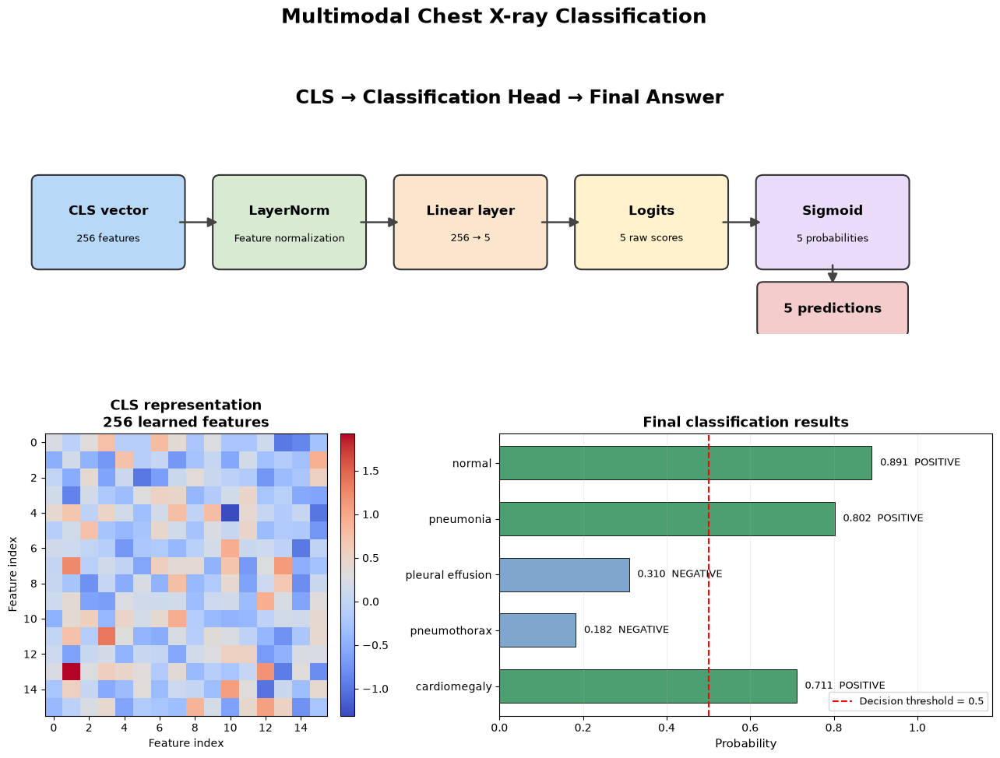


FINAL MODEL PREDICTIONS
normal               | 0.891 | POSITIVE
pneumonia            | 0.802 | POSITIVE
pleural effusion     | 0.310 | NEGATIVE
pneumothorax         | 0.182 | NEGATIVE
cardiomegaly         | 0.711 | POSITIVE
Decision threshold: 0.5


In [8]:

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch
from IPython.display import display, clear_output
import time

# ============================================================
# 1. CLASS DEFINITIONS
# ============================================================

PROMPTS = {
    "normal": "normal chest X-ray with no acute findings",
    "pneumonia": "chest X-ray showing pneumonia",
    "pleural effusion": "chest X-ray showing pleural effusion",
    "pneumothorax": "chest X-ray showing pneumothorax",
    "cardiomegaly": "chest X-ray showing cardiomegaly",
}

class_names = list(PROMPTS.keys())
NUM_CLASSES = len(class_names)

# ============================================================
# 2. VISUALIZATION FUNCTION
# ============================================================

def visualize_cls_pipeline(cls_vector, logits, animate=True,
                           threshold=0.5):

    cls_vector = np.asarray(cls_vector).reshape(-1)
    logits = np.asarray(logits).reshape(-1)

    assert cls_vector.shape[0] == 256, (
        f"Expected 256 CLS features, received {len(cls_vector)}"
    )
    assert logits.shape[0] == NUM_CLASSES, (
        f"Expected {NUM_CLASSES} logits, received {len(logits)}"
    )

    # Numerically stable sigmoid
    probabilities = np.where(
        logits >= 0,
        1 / (1 + np.exp(-logits)),
        np.exp(logits) / (1 + np.exp(logits))
    )

    predictions = probabilities >= threshold

    # --------------------------------------------------------
    # FIGURE
    # --------------------------------------------------------

    fig = plt.figure(figsize=(16, 10))
    gs = fig.add_gridspec(
        2, 2,
        height_ratios=[1, 1.3],
        width_ratios=[1, 1.5],
        hspace=0.4,
        wspace=0.35
    )

    # --------------------------------------------------------
    # 3. PIPELINE DIAGRAM
    # --------------------------------------------------------

    ax = fig.add_subplot(gs[0, :])
    ax.set_xlim(0, 16)
    ax.set_ylim(0, 4)
    ax.axis("off")

    def draw_box(x, title, subtitle, color, width=2.3):
        box = FancyBboxPatch(
            (x, 1.3), width, 1.5,
            boxstyle="round,pad=0.12",
            facecolor=color,
            edgecolor="#333333",
            linewidth=1.5
        )
        ax.add_patch(box)

        ax.text(
            x + width / 2, 2.25, title,
            ha="center", va="center",
            fontsize=12, fontweight="bold"
        )
        ax.text(
            x + width / 2, 1.75, subtitle,
            ha="center", va="center",
            fontsize=9
        )

    def draw_arrow(x1, x2):
        ax.add_patch(FancyArrowPatch(
            (x1, 2.05), (x2, 2.05),
            arrowstyle="-|>",
            mutation_scale=18,
            linewidth=1.8,
            color="#444444"
        ))

    positions = [0.2, 3.2, 6.2, 9.2, 12.2]

    stages = [
        ("CLS vector", "256 features", "#B7D9F7"),
        ("LayerNorm", "Feature normalization", "#D9EAD3"),
        ("Linear layer", "256 → 5", "#FCE5CD"),
        ("Logits", "5 raw scores", "#FFF2CC"),
        ("Sigmoid", "5 probabilities", "#EADCF8"),
    ]

    for x, (title, subtitle, color) in zip(positions, stages):
        draw_box(x, title, subtitle, color)

    for i in range(len(positions) - 1):
        draw_arrow(positions[i] + 2.3, positions[i + 1])

    # Final answer box
    answer_box = FancyBboxPatch(
        (12.2, 0.05), 2.3, 0.8,
        boxstyle="round,pad=0.1",
        facecolor="#F4CCCC",
        edgecolor="#333333",
        linewidth=1.5
    )
    ax.add_patch(answer_box)

    ax.text(
        13.35, 0.45,
        "5 predictions",
        ha="center", va="center",
        fontsize=12, fontweight="bold"
    )

    ax.add_patch(FancyArrowPatch(
        (13.35, 1.3), (13.35, 0.88),
        arrowstyle="-|>",
        mutation_scale=18,
        linewidth=1.8,
        color="#444444"
    ))

    ax.set_title(
        "CLS → Classification Head → Final Answer",
        fontsize=17, fontweight="bold", pad=12
    )

    # --------------------------------------------------------
    # 4. CLS FEATURE HEATMAP
    # --------------------------------------------------------

    ax1 = fig.add_subplot(gs[1, 0])

    feature_map = cls_vector.reshape(16, 16)

    im = ax1.imshow(
        feature_map,
        cmap="coolwarm",
        interpolation="nearest",
        aspect="equal"
    )

    ax1.set_title(
        "CLS representation\n256 learned features",
        fontsize=13,
        fontweight="bold"
    )
    ax1.set_xlabel("Feature index")
    ax1.set_ylabel("Feature index")

    plt.colorbar(im, ax=ax1, fraction=0.046, pad=0.04)

    # --------------------------------------------------------
    # 5. FINAL FIVE CLASS PREDICTIONS
    # --------------------------------------------------------

    ax2 = fig.add_subplot(gs[1, 1])

    y = np.arange(NUM_CLASSES)

    bars = ax2.barh(
        y,
        probabilities,
        height=0.6,
        color=[
            "#4C9F70" if p >= threshold else "#7FA6CC"
            for p in probabilities
        ],
        edgecolor="black",
        linewidth=0.6
    )

    ax2.axvline(
        threshold,
        color="red",
        linestyle="--",
        linewidth=1.5,
        label=f"Decision threshold = {threshold}"
    )

    ax2.set_yticks(y)
    ax2.set_yticklabels(class_names, fontsize=10)
    ax2.invert_yaxis()

    ax2.set_xlim(0, 1.18)
    ax2.set_xlabel("Probability", fontsize=11)
    ax2.set_title(
        "Final classification results",
        fontsize=13,
        fontweight="bold"
    )

    ax2.grid(axis="x", alpha=0.2)
    ax2.legend(loc="lower right", fontsize=9)

    for i, bar in enumerate(bars):
        status = "POSITIVE" if predictions[i] else "NEGATIVE"

        ax2.text(
            probabilities[i] + 0.02,
            bar.get_y() + bar.get_height() / 2,
            f"{probabilities[i]:.3f}  {status}",
            va="center",
            fontsize=9
        )

    plt.suptitle(
        "Multimodal Chest X-ray Classification",
        fontsize=19,
        fontweight="bold",
        y=1.02
    )

    plt.tight_layout()
    plt.show()

    # --------------------------------------------------------
    # 6. PRINT FINAL ANSWER
    # --------------------------------------------------------

    print("\nFINAL MODEL PREDICTIONS")
    print("=" * 48)

    for name, probability, prediction in zip(
        class_names, probabilities, predictions
    ):
        print(
            f"{name:20s} | "
            f"{probability:.3f} | "
            f"{'POSITIVE' if prediction else 'NEGATIVE'}"
        )

    print("=" * 48)
    print(f"Decision threshold: {threshold}")

    return probabilities, predictions


# ============================================================
# 7. CONNECT TO YOUR TRAINED MODEL
# ============================================================

# Example for real model inference:
#
# model.eval()
#
# with torch.no_grad():
#     # Adapt this to your model's forward method.
#     logits = model(image, text)
#
#     # If your forward method returns logits directly:
#     cls_vector = model_output_cls
#
# visualize_cls_pipeline(
#     cls_vector[0].detach().cpu().numpy(),
#     logits[0].detach().cpu().numpy()
# )


# ============================================================
# 8. DEMONSTRATION MODE
# ============================================================

# Set this to True when you want to demonstrate the pipeline
# without running your trained model.

DEMO_MODE = True

if DEMO_MODE:
    np.random.seed(42)

    demo_cls = np.random.randn(256) * 0.5

    # Illustrative logits only, not actual model predictions
    demo_logits = np.array([2.1, 1.4, -0.8, -1.5, 0.9])

    visualize_cls_pipeline(
        demo_cls,
        demo_logits,
        animate=True,
        threshold=0.5
    )
